In [3]:
import os
import glob
import json
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import numpy as np
import random
from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
import pprint
import pyspark
import pyspark.sql.functions as F

from pyspark.sql.functions import col
from pyspark.sql.types import StringType, IntegerType, FloatType, DateType

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score, roc_auc_score, brier_score_loss, log_loss
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

from utils.psi import build_reference
import shap

In [4]:
# Initialize SparkSession
spark = pyspark.sql.SparkSession.builder \
    .appName("dev") \
    .master("local[*]") \
    .getOrCreate()

# Set log level to ERROR to hide warnings
spark.sparkContext.setLogLevel("ERROR")

## Set up config

In [5]:
# set up config
model_train_date_str = "2024-09-01"
train_test_period_months = 12
oot_period_months = 2
train_test_ratio = 0.8

config = {}
config["model_train_date_str"] = model_train_date_str
config["train_test_period_months"] = train_test_period_months
config["oot_period_months"] =  oot_period_months
config["model_train_date"] =  datetime.strptime(model_train_date_str, "%Y-%m-%d")
config["oot_end_date"] =  config['model_train_date'] - timedelta(days = 1)
config["oot_start_date"] =  config['model_train_date'] - relativedelta(months = oot_period_months)
config["train_test_end_date"] =  config["oot_start_date"] - timedelta(days = 1)
config["train_test_start_date"] =  config["oot_start_date"] - relativedelta(months = train_test_period_months)
config["train_test_ratio"] = train_test_ratio 


pprint.pprint(config)

{'model_train_date': datetime.datetime(2024, 9, 1, 0, 0),
 'model_train_date_str': '2024-09-01',
 'oot_end_date': datetime.datetime(2024, 8, 31, 0, 0),
 'oot_period_months': 2,
 'oot_start_date': datetime.datetime(2024, 7, 1, 0, 0),
 'train_test_end_date': datetime.datetime(2024, 6, 30, 0, 0),
 'train_test_period_months': 12,
 'train_test_ratio': 0.8,
 'train_test_start_date': datetime.datetime(2023, 7, 1, 0, 0)}


## Get labels store

In [6]:
folder_path = "datamart/gold/label_store/"
files_list = [folder_path + os.path.basename(file) for file in glob.glob(os.path.join(folder_path, "*")) ]
print("files_list: ", files_list)
label_store_sdf = spark.read.option("header", "true").parquet(*files_list)
print("label_store_sdf count: ", label_store_sdf.count())
label_store_sdf.show()

files_list:  ['datamart/gold/label_store/gold_label_store_2024_02_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_07_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_07_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_02_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_08_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_11_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_05_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_05_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_08_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_11_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_06_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_03_01.parquet', 'datamart/gold/label_store/gold_label_store_2023_12_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_12_01.parquet', 'datamart/gold/label_store/gold_label_store_2024_03_01.parquet', 'datamart/g

label_store_sdf count:  8974
+--------------------+-----------+-----+----------+-------------+---------------------+
|             loan_id|customer_id|label| label_def|snapshot_date|feature_snapshot_date|
+--------------------+-----------+-----+----------+-------------+---------------------+
|CUS_0x1037_2023_0...| CUS_0x1037|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x1069_2023_0...| CUS_0x1069|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x114a_2023_0...| CUS_0x114a|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x1184_2023_0...| CUS_0x1184|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x1297_2023_0...| CUS_0x1297|    1|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x12fb_2023_0...| CUS_0x12fb|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x1325_2023_0...| CUS_0x1325|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CUS_0x1341_2023_0...| CUS_0x1341|    0|30dpd_6mob|   2023-07-01|           2023-01-01|
|CU

In [7]:
labels_sdf = label_store_sdf.filter((col("snapshot_date") >= config["train_test_start_date" ]) & (col("snapshot_date") <= config["oot_end_date" ]))
print("excepted labels_sdf count: ", labels_sdf.count(), config["train_test_start_date"], config["oot_end_date"])

excepted labels_sdf count:  6961 2023-07-01 00:00:00 2024-08-31 00:00:00


In [8]:
feature_folder_path = "datamart/gold/features_store/"
feature_files_list = [feature_folder_path + os.path.basename(file) for file in glob.glob(os.path.join(feature_folder_path, "*")) ]
print("feature_files_list: ", feature_files_list)
feature_store_sdf = spark.read.option("header", "true").parquet(*feature_files_list)
print("feature_store_sdf count: ", feature_store_sdf.count())
feature_store_sdf.show()

feature_files_list:  ['datamart/gold/features_store/gold_features_store_2024_09_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_10_01.parquet', 'datamart/gold/features_store/gold_features_store_2024_04_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_01_01.parquet', 'datamart/gold/features_store/gold_features_store_2024_01_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_04_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_09_01.parquet', 'datamart/gold/features_store/gold_features_store_2024_10_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_12_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_03_01.parquet', 'datamart/gold/features_store/gold_features_store_2024_06_01.parquet', 'datamart/gold/features_store/gold_features_store_2023_06_01.parquet', 'datamart/gold/features_store/gold_features_store_2024_03_01.parquet', 'datamart/gold/features_store/gold_features_store_2024_

In [9]:
# features are dated at loan start; the label store carries that date as feature_snapshot_date
features_sdf = feature_store_sdf.withColumnRenamed("snapshot_date", "feature_snapshot_date")
print("features_sdf count: ", features_sdf.count())

features_sdf count:  11974


## Prepare data for modeling

In [10]:
data_pdf = labels_sdf.join(features_sdf, on=["customer_id", "feature_snapshot_date"], how="left").toPandas()
# has_clickstream is never null in the feature store, so a null here means the join missed
print("rows without features:", data_pdf["has_clickstream"].isna().sum(), "/", len(data_pdf))
data_pdf

rows without features: 0 / 6961


,customer_id,feature_snapshot_date,loan_id,label,label_def,snapshot_date,age,occupation,annual_income,monthly_inhand_salary,...,fe_12_mean_12m,fe_13_mean_12m,fe_14_mean_12m,fe_15_mean_12m,fe_16_mean_12m,fe_17_mean_12m,fe_18_mean_12m,fe_19_mean_12m,fe_20_mean_12m,has_clickstream
0,CUS_0x1037,2023-01-01,CUS_0x1037_2023_01_01,0,30dpd_6mob,2023-07-01,45.0,Accountant,15989.080078,1086.420044,...,105.000000,-16.000000,-81.000000,-126.000000,114.000000,35.000000,85.000000,-73.000000,76.000000,1
1,CUS_0x1069,2023-01-01,CUS_0x1069_2023_01_01,0,30dpd_6mob,2023-07-01,32.0,Accountant,58637.339844,4799.439941,...,190.000000,-14.000000,-96.000000,200.000000,35.000000,130.000000,94.000000,111.000000,75.000000,1
2,CUS_0x114a,2023-01-01,CUS_0x114a_2023_01_01,0,30dpd_6mob,2023-07-01,43.0,Developer,15305.459961,1230.449951,...,203.000000,26.000000,86.000000,171.000000,125.000000,-130.000000,354.000000,17.000000,302.000000,1
3,CUS_0x1184,2023-01-01,CUS_0x1184_2023_01_01,0,30dpd_6mob,2023-07-01,49.0,Lawyer,19867.470703,1396.619995,...,197.000000,172.000000,96.000000,174.000000,163.000000,37.000000,207.000000,180.000000,118.000000,1
4,CUS_0x1297,2023-01-01,CUS_0x1297_2023_01_01,1,30dpd_6mob,2023-07-01,46.0,Manager,57738.058594,4881.500000,...,12.000000,76.000000,43.000000,183.000000,159.000000,-26.000000,104.000000,118.000000,184.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6956,CUS_0xdf6,2023-09-01,CUS_0xdf6_2023_09_01,0,30dpd_6mob,2024-03-01,55.0,Mechanic,40453.851562,2772.810059,...,175.444444,103.111111,111.222222,50.444444,98.444444,36.111111,144.333333,100.777778,119.777778,1
6957,CUS_0xe23,2023-09-01,CUS_0xe23_2023_09_01,0,30dpd_6mob,2024-03-01,39.0,Musician,17815.589844,1427.630005,...,117.888889,143.666667,76.222222,158.555556,86.666667,70.777778,90.333333,85.000000,33.111111,1
6958,CUS_0xe4e,2023-09-01,CUS_0xe4e_2023_09_01,0,30dpd_6mob,2024-03-01,22.0,Scientist,108073.679688,8738.139648,...,87.888889,104.888889,126.333333,111.666667,196.000000,116.666667,81.333333,108.222222,52.888889,1
6959,CUS_0xedd,2023-09-01,CUS_0xedd_2023_09_01,0,30dpd_6mob,2024-03-01,NaN,Engineer,125468.437500,10445.700195,...,85.000000,92.111111,126.777778,156.555556,103.000000,50.888889,79.888889,134.777778,77.111111,1


## Split data into train test oot

In [11]:
oot_pdf = data_pdf[
    (data_pdf["snapshot_date"] >= config["oot_start_date"].date())
    & (data_pdf["snapshot_date"] <= config["oot_end_date"].date())
]
train_test_pdf = data_pdf[
    (data_pdf["snapshot_date"] >= config["train_test_start_date"].date())
    & (data_pdf["snapshot_date"] <= config["train_test_end_date"].date())
]
feature_cols = [
    col
    for col in data_pdf.columns
    if col not in ["customer_id", "snapshot_date", "feature_snapshot_date", "label", "label_def", "loan_id"]
]

X_oot = oot_pdf[feature_cols]
y_oot = oot_pdf["label"]
X_train_test = train_test_pdf[feature_cols]

# no separate val set: hyperparameters are tuned with cross-validation on train
X_train, X_test, y_train, y_test = train_test_split(
    X_train_test,
    train_test_pdf["label"],
    test_size=1 - config["train_test_ratio"],
    random_state=42,
    shuffle=True,
    stratify=train_test_pdf["label"],
)

print("X_train shape: ", X_train.shape[0])
print("X_test shape: ", X_test.shape[0])
print("X_oot shape: ", X_oot.shape[0])
print("y_train shape: ", y_train.shape[0], round(y_train.mean(), 2))
print("y_test shape: ", y_test.shape[0], round(y_test.mean(), 2))
print("y_oot shape: ", y_oot.shape[0], round(y_oot.mean(), 2))

X_train shape:  4766
X_test shape:  1192
X_oot shape:  1003
y_train shape:  4766 0.28
y_test shape:  1192 0.28
y_oot shape:  1003 0.29


## Process data

In [12]:
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(exclude="object").columns.tolist()

print("categorical:", cat_cols)

scaler = StandardScaler()
transformer = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', scaler)
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_cols)
]).fit(X_train)

X_train_processed = transformer.transform(X_train)
X_test_processed = transformer.transform(X_test)
X_oot_processed = transformer.transform(X_oot)

print('X_train_processed', X_train_processed.shape[0])
print('X_test_processed', X_test_processed.shape[0])
print('X_oot_processed', X_oot_processed.shape[0])

pd.DataFrame(X_train_processed, columns=transformer.get_feature_names_out())

categorical: ['occupation', 'credit_mix', 'payment_of_min_amount']
X_train_processed 4766
X_test_processed 1192
X_oot_processed 1003


,num__age,num__annual_income,num__monthly_inhand_salary,num__num_bank_accounts,num__num_credit_card,num__interest_rate,num__num_of_loan,num__delay_from_due_date,num__num_of_delayed_payment,num__changed_credit_limit,...,cat__occupation_Teacher,cat__occupation_Writer,cat__occupation_None,cat__credit_mix_Bad,cat__credit_mix_Good,cat__credit_mix_Standard,cat__credit_mix_None,cat__payment_of_min_amount_NM,cat__payment_of_min_amount_No,cat__payment_of_min_amount_Yes
0,0.660489,-0.119688,-1.185482,0.636141,0.736203,0.301013,2.251343,2.776437,1.738739,1.613566,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.380947,-0.068249,0.649064,-0.140260,0.736203,-1.203880,-0.637476,-1.223284,-1.865584,-0.420520,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2,1.689715,-0.102136,-0.492395,-0.528461,-0.246638,-0.856597,-0.224788,0.471513,-0.554921,0.180798,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.351721,-0.102898,-0.527466,1.800742,2.210464,1.921666,0.600589,-0.206405,0.428076,-1.115375,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-1.397964,-0.092726,-0.165653,-0.140260,-1.720899,-0.277792,-1.050165,-0.545365,-1.701751,-0.273531,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4761,1.586792,-0.034221,1.886239,-1.304862,-2.212320,-0.625075,-0.224788,-0.884324,-2.193250,0.102107,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4762,-1.603809,-0.110145,-0.767497,-1.693062,-1.229479,-0.856597,-0.637476,-0.138613,-2.029417,-0.805066,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4763,1.483870,-0.111049,-0.728546,-2.081263,-0.738059,-0.856597,-1.462853,-0.680949,-0.718754,-0.263138,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4764,-0.265815,-0.112458,-0.948603,0.636141,2.210464,-0.162031,1.425966,2.098519,0.428076,-1.305421,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


## Train model

In [13]:
xgb_clf = xgb.XGBClassifier(eval_metric='logloss', random_state=42)

param_dist = {
    'n_estimators': [25, 50],
    'max_depth': [2, 3],  # lower max_depth to simplify the model
    'learning_rate': [0.01, 0.1],
    'subsample': [0.6, 0.8],
    'colsample_bytree': [0.6, 0.8],
    'gamma': [0, 0.1],
    'min_child_weight': [1, 3, 5],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 1.5, 2]
}

random_search = RandomizedSearchCV(
    estimator=xgb_clf,
    param_distributions=param_dist,
    scoring="roc_auc",  # uses predict_proba; make_scorer(roc_auc_score) would score hard 0/1 predictions
    n_iter=10,  # Number of iterations for random search
    cv=3,       # Number of folds in cross-validation
    verbose=1,
    random_state=42,
    n_jobs=-1   # Use all available cores
)

random_search.fit(X_train_processed, y_train)

print("Best parameters found: ", random_search.best_params_)
print("Best AUC score: ", random_search.best_score_)

best_model = random_search.best_estimator_

y_pred_proba = best_model.predict_proba(X_train_processed)[:, 1]
train_auc_score = roc_auc_score(y_train, y_pred_proba)
print("Train AUC score: ", train_auc_score)

# Evaluate the model on the test set
best_model = random_search.best_estimator_
y_pred_proba = best_model.predict_proba(X_test_processed)[:, 1]
test_auc_score = roc_auc_score(y_test, y_pred_proba)
print("Test AUC score: ", test_auc_score)

# Evaluate the model on the oot set
best_model = random_search.best_estimator_
y_pred_proba = best_model.predict_proba(X_oot_processed)[:, 1]
oot_auc_score = roc_auc_score(y_oot, y_pred_proba)
print("OOT AUC score: ", oot_auc_score)

print("TRAIN GINI score: ", round(2*train_auc_score-1,3))
print("Test GINI score: ", round(2*test_auc_score-1,3))
print("OOT GINI score: ", round(2*oot_auc_score-1,3))
best_model.predict_proba(X_oot_processed)[:,1]

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters found:  {'subsample': 0.6, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 50, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.8}
Best AUC score:  0.8595590616143558
Train AUC score:  0.9049525190512792
Test AUC score:  0.8699082027521822
OOT AUC score:  0.9038959033167303
TRAIN GINI score:  0.81
Test GINI score:  0.74
OOT GINI score:  0.808


array([0.44896176, 0.9030986 , 0.20643279, ..., 0.6948065 , 0.15735917,
       0.80631983], shape=(1003,), dtype=float32)

In [14]:

importance_df = pd.DataFrame({
    "feature": transformer.get_feature_names_out(),
    "importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

print(importance_df)

                           feature  importance
11           num__outstanding_debt    0.134236
57             cat__credit_mix_Bad    0.118701
5               num__interest_rate    0.074065
7         num__delay_from_due_date    0.038598
24              num__fe_5_mean_12m    0.037047
..                             ...         ...
41      cat__occupation_Accountant    0.000000
40            num__has_clickstream    0.000000
12   num__credit_utilization_ratio    0.000000
6                 num__num_of_loan    0.000000
63  cat__payment_of_min_amount_Yes    0.000000

[64 rows x 2 columns]


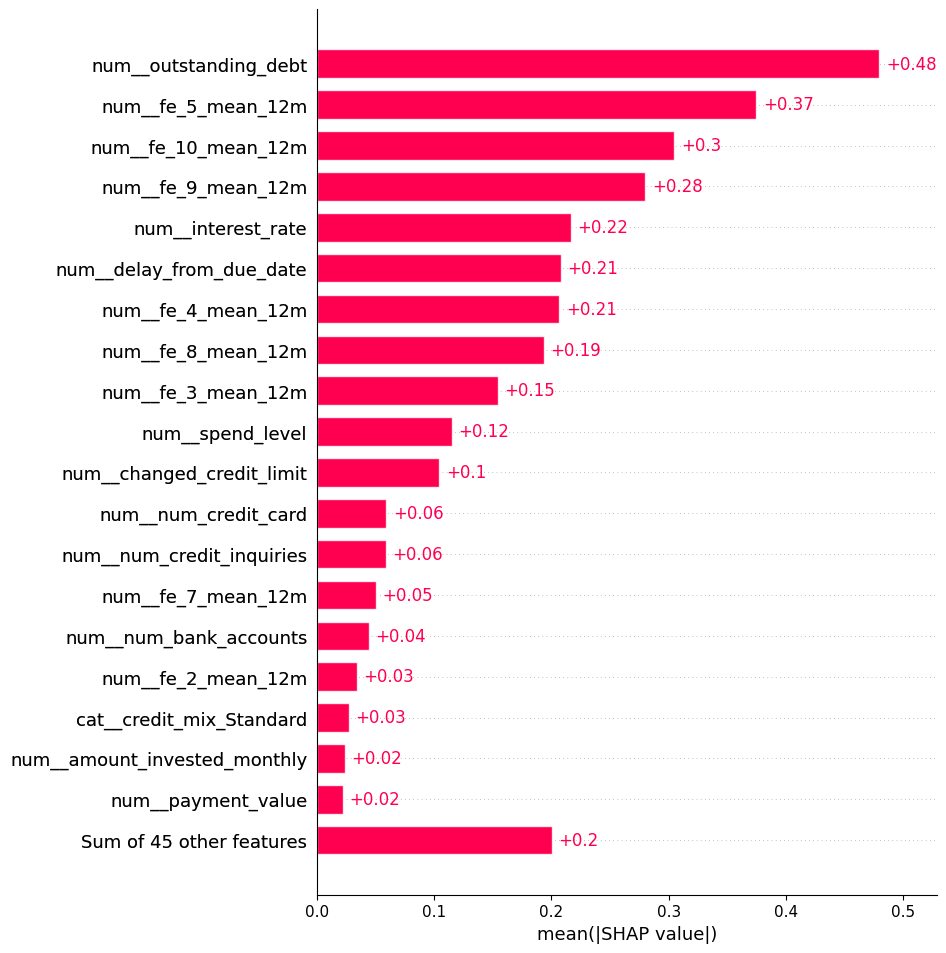

In [15]:
# Use your preprocessed test data
explainer = shap.TreeExplainer(best_model)

shap_values = explainer(X_test_processed)

feature_names = transformer.get_feature_names_out()
shap_values.feature_names = list(feature_names)
shap.plots.bar(shap_values, max_display=20)

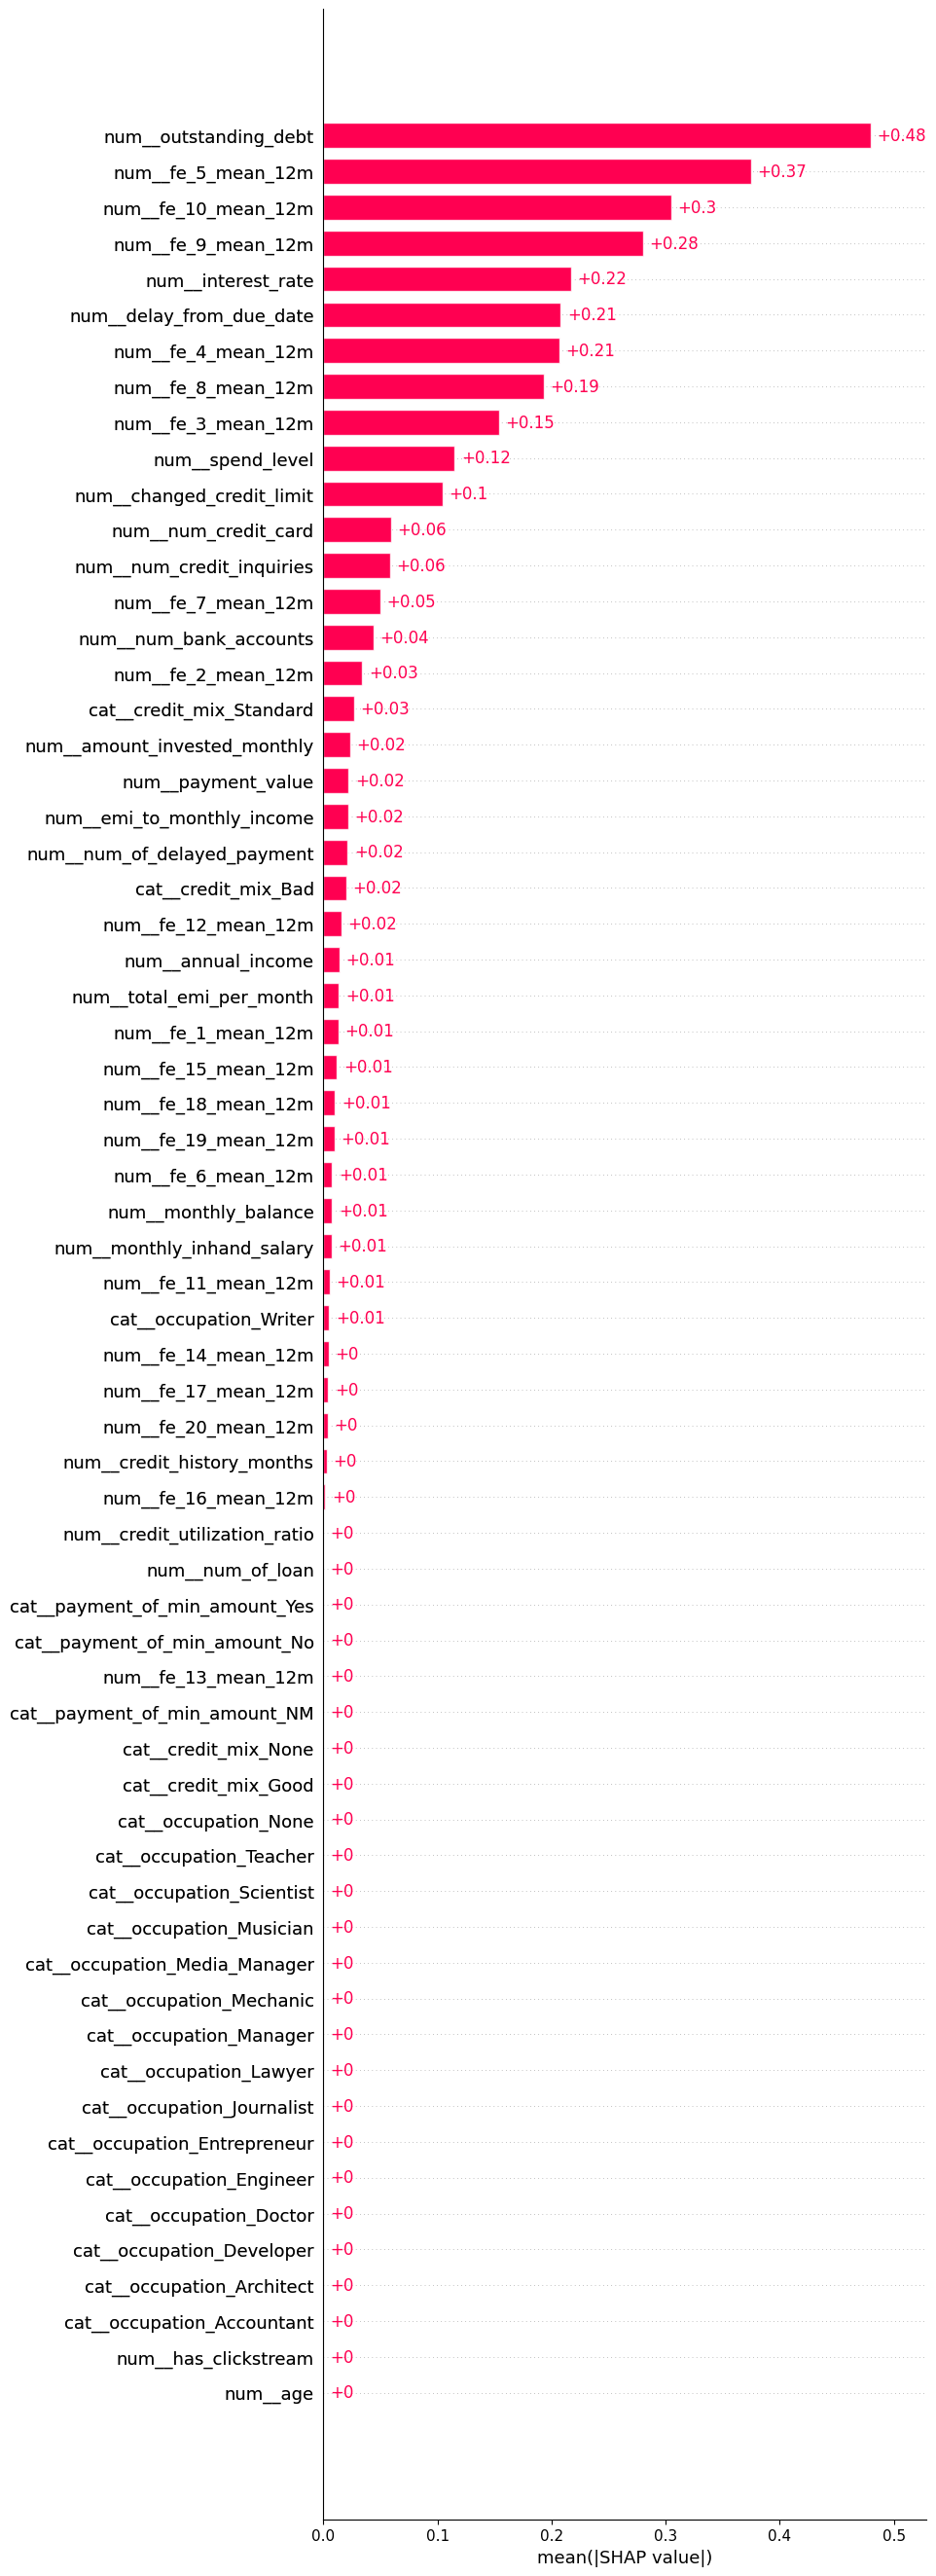

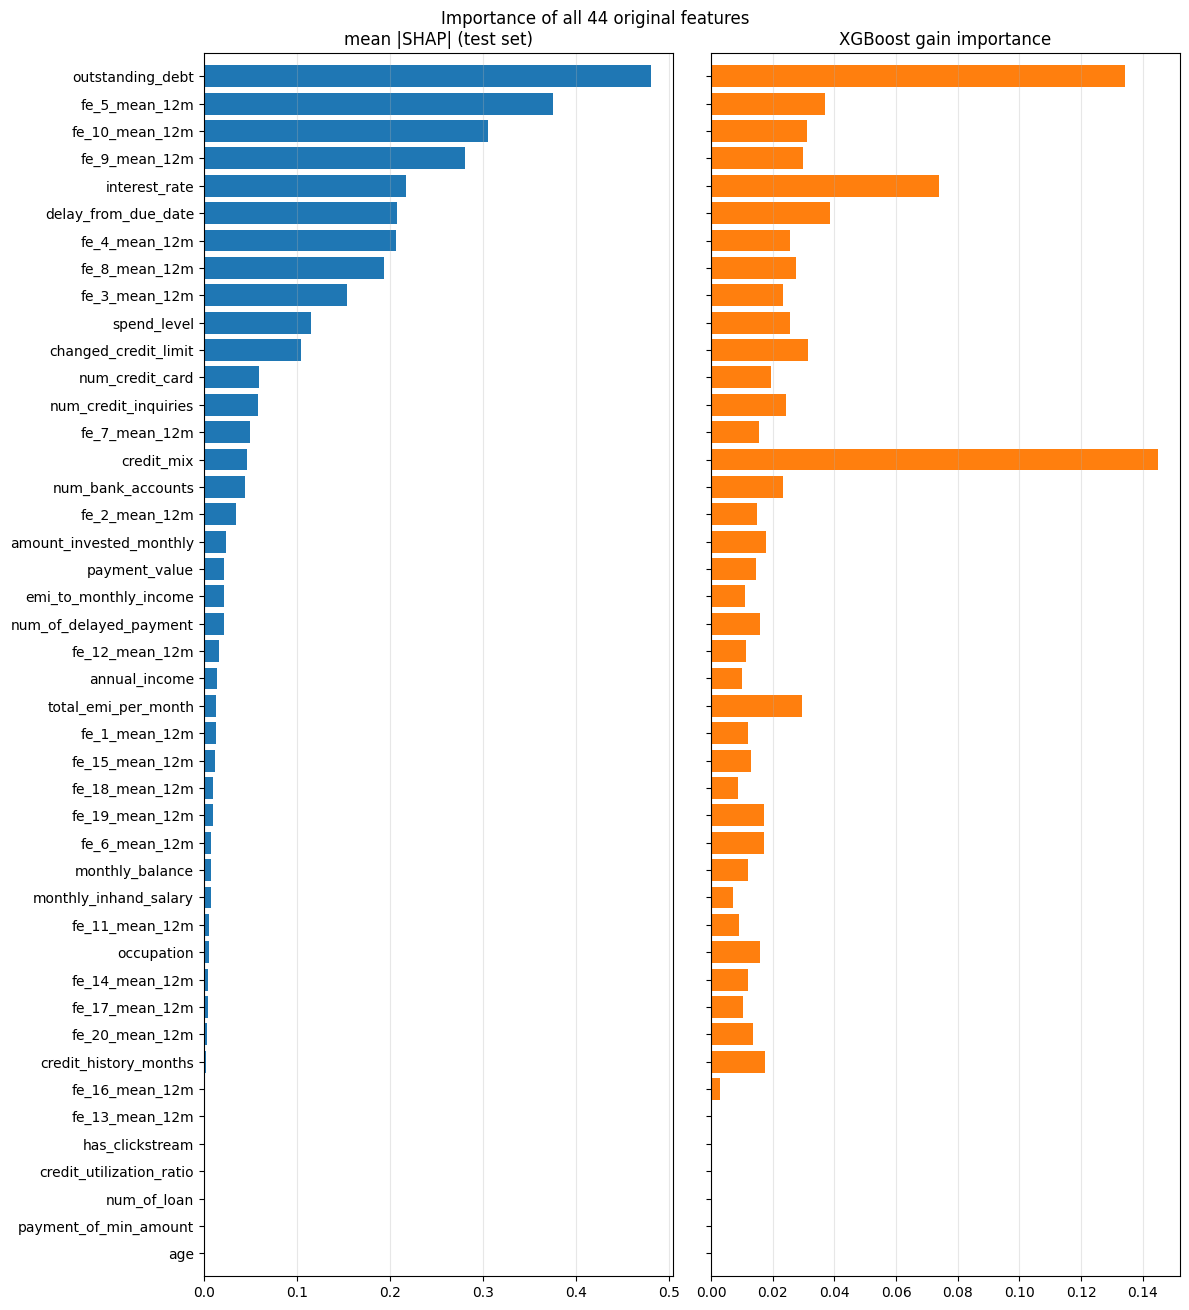

,shap,gain
outstanding_debt,0.479722,0.134236
fe_5_mean_12m,0.374723,0.037047
fe_10_mean_12m,0.304803,0.031002
fe_9_mean_12m,0.280029,0.029759
interest_rate,0.216801,0.074065
delay_from_due_date,0.207969,0.038598
fe_4_mean_12m,0.206582,0.025579
fe_8_mean_12m,0.193321,0.027664
fe_3_mean_12m,0.154050,0.023192
spend_level,0.115086,0.025725


In [16]:
# every model column, nothing folded into "other features"
shap.plots.bar(shap_values, max_display=len(feature_names))

# one-hot columns summed back to the original feature, since that's the level you keep or drop
def raw_name(name):
    name = name.split('__', 1)[1]  # strip 'num__' / 'cat__'
    return next((c for c in cat_cols if name.startswith(c + '_')), name)

raw_importance_df = pd.DataFrame({
    'shap': pd.Series(np.abs(shap_values.values).mean(0), index=feature_names).groupby(raw_name).sum(),
    'gain': pd.Series(best_model.feature_importances_, index=feature_names).groupby(raw_name).sum(),
}).sort_values('shap')

fig, (ax_shap, ax_gain) = plt.subplots(1, 2, figsize=(12, 0.28 * len(raw_importance_df) + 1), sharey=True)
ax_shap.barh(raw_importance_df.index, raw_importance_df['shap'])
ax_shap.set_title('mean |SHAP| (test set)')
ax_gain.barh(raw_importance_df.index, raw_importance_df['gain'], color='tab:orange')
ax_gain.set_title('XGBoost gain importance')
for ax in (ax_shap, ax_gain):
    ax.margins(y=0.01)
    ax.grid(axis='x', alpha=0.3)
fig.suptitle(f'Importance of all {len(raw_importance_df)} original features')
plt.tight_layout()
plt.show()

raw_importance_df.sort_values('shap', ascending=False)

In [17]:
from sklearn.model_selection import cross_val_score

# candidate feature sets cut from the mean |SHAP| ranking
shap_ranking = raw_importance_df.sort_values('shap', ascending=False).index.tolist()
feature_sets = {
    'top 8': shap_ranking[:8],
    'top 11': shap_ranking[:11],  # biggest gap in the chart, after changed_credit_limit
    'top 11 + credit_mix': shap_ranking[:11] + ['credit_mix'],  # low SHAP but highest gain
    'top 17': shap_ranking[:17],  # second gap, after fe_2_mean_12m
    'top 23': shap_ranking[:shap_ranking.index('annual_income') + 1],
}
print("top 11:", feature_sets['top 11'])

def make_pipe(cols):
    # same preprocessing and hyperparameters as the full model, so only the feature set differs
    prep = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), [c for c in num_cols if c in cols]),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), [c for c in cat_cols if c in cols])
    ])
    return Pipeline([
        ('prep', prep),
        ('model', xgb.XGBClassifier(eval_metric='logloss', random_state=42, **random_search.best_params_)),
    ])

def score(model, X_tr, X_te, X_o):
    p_test, p_oot = model.predict_proba(X_te)[:, 1], model.predict_proba(X_o)[:, 1]
    return {
        'auc_train': roc_auc_score(y_train, model.predict_proba(X_tr)[:, 1]),
        'auc_test': roc_auc_score(y_test, p_test),
        'auc_oot': roc_auc_score(y_oot, p_oot),
        'brier_oot': brier_score_loss(y_oot, p_oot),
    }

results = {
    'full': {'n_features': len(feature_cols), 'cv_auc': random_search.best_score_,
             **score(best_model, X_train_processed, X_test_processed, X_oot_processed)},
}
fitted_pipes = {}
for name, cols in feature_sets.items():
    pipe = make_pipe(cols)
    cv_auc = cross_val_score(pipe, X_train[cols], y_train, cv=3, scoring='roc_auc').mean()
    pipe.fit(X_train[cols], y_train)
    fitted_pipes[name] = pipe
    results[name] = {'n_features': len(cols), 'cv_auc': cv_auc,
                     **score(pipe, X_train[cols], X_test[cols], X_oot[cols])}

feature_set_comparison = pd.DataFrame(results).T
# pick on cv_auc: test was used to rank the features, and OOT should stay a final check
feature_set_comparison['cv_auc_vs_full'] = feature_set_comparison['cv_auc'] - feature_set_comparison.loc['full', 'cv_auc']
feature_set_comparison.round(4)

top 11: ['outstanding_debt', 'fe_5_mean_12m', 'fe_10_mean_12m', 'fe_9_mean_12m', 'interest_rate', 'delay_from_due_date', 'fe_4_mean_12m', 'fe_8_mean_12m', 'fe_3_mean_12m', 'spend_level', 'changed_credit_limit']


,n_features,cv_auc,auc_train,auc_test,auc_oot,brier_oot,cv_auc_vs_full
full,44.0,0.8596,0.9050,0.8699,0.9039,0.1149,0.0000
top 8,8.0,0.8506,0.8814,0.8466,0.8884,0.1196,-0.0090
top 11,11.0,0.8572,0.8908,0.8572,0.8991,0.1155,-0.0024
top 11 + credit_mix,12.0,0.8579,0.8931,0.8596,0.9019,0.1142,-0.0016
top 17,17.0,0.8614,0.8986,0.8697,0.9024,0.1145,0.0019
top 23,23.0,0.8623,0.9017,0.8717,0.9074,0.1133,0.0027


Train AUC score:  0.9048671524859461
Test AUC score:  0.871546323771843
OOT AUC score:  0.9053438356693309
       raw  OOT Brier: 0.1149  log loss: 0.3691
calibrated  OOT Brier: 0.1134  log loss: 0.3650


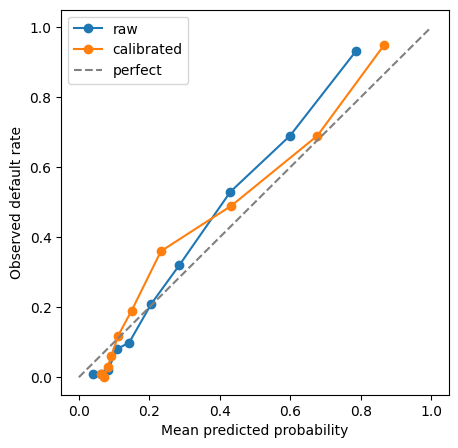

In [18]:
# refit the tuned xgboost inside 3-fold calibration, so the calibrator only learns from out-of-fold predictions
calibrated_model = CalibratedClassifierCV(
    xgb.XGBClassifier(eval_metric='logloss', random_state=42, **random_search.best_params_),
    method='sigmoid',
    cv=3,
)
calibrated_model.fit(X_train_processed, y_train)

# train AUC is part in-sample, part out-of-fold here, so it isn't comparable to the raw model's
cal_train_auc_score = roc_auc_score(y_train, calibrated_model.predict_proba(X_train_processed)[:, 1])
cal_test_auc_score = roc_auc_score(y_test, calibrated_model.predict_proba(X_test_processed)[:, 1])
cal_oot_auc_score = roc_auc_score(y_oot, calibrated_model.predict_proba(X_oot_processed)[:, 1])
print("Train AUC score: ", cal_train_auc_score)
print("Test AUC score: ", cal_test_auc_score)
print("OOT AUC score: ", cal_oot_auc_score)

# AUC barely moves with calibration; Brier and log loss show whether the probabilities improved
fig, ax = plt.subplots(figsize=(5, 5))
for name, model in [('raw', best_model), ('calibrated', calibrated_model)]:
    p = model.predict_proba(X_oot_processed)[:, 1]
    print(f"{name:>10}  OOT Brier: {brier_score_loss(y_oot, p):.4f}  log loss: {log_loss(y_oot, p):.4f}")
    frac_pos, mean_pred = calibration_curve(y_oot, p, n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_pos, marker='o', label=name)

ax.plot([0, 1], [0, 1], '--', color='grey', label='perfect')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Observed default rate')
ax.legend()
plt.show()

In [19]:
lr_clf = LogisticRegression(max_iter=1000, random_state=42)

lr_param_dist = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],  # smaller C = stronger regularisation
    'class_weight': [None, 'balanced']
}

lr_random_search = RandomizedSearchCV(
    estimator=lr_clf,
    param_distributions=lr_param_dist,
    scoring="roc_auc",
    n_iter=10,  # Number of iterations for random search
    cv=3,       # Number of folds in cross-validation
    verbose=1,
    random_state=42,
    n_jobs=-1   # Use all available cores
)

lr_random_search.fit(X_train_processed, y_train)

print("Best parameters found: ", lr_random_search.best_params_)
print("Best AUC score: ", lr_random_search.best_score_)

lr_best_model = lr_random_search.best_estimator_

lr_train_auc_score = roc_auc_score(y_train, lr_best_model.predict_proba(X_train_processed)[:, 1])
print("Train AUC score: ", lr_train_auc_score)

# Evaluate the model on the test set
lr_test_auc_score = roc_auc_score(y_test, lr_best_model.predict_proba(X_test_processed)[:, 1])
print("Test AUC score: ", lr_test_auc_score)

# Evaluate the model on the oot set
lr_oot_auc_score = roc_auc_score(y_oot, lr_best_model.predict_proba(X_oot_processed)[:, 1])
print("OOT AUC score: ", lr_oot_auc_score)

print("TRAIN GINI score: ", round(2*lr_train_auc_score-1,3))
print("Test GINI score: ", round(2*lr_test_auc_score-1,3))
print("OOT GINI score: ", round(2*lr_oot_auc_score-1,3))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters found:  {'class_weight': None, 'C': 0.1}
Best AUC score:  0.8415642503090758
Train AUC score:  0.8535563147069346
Test AUC score:  0.861360126329672
OOT AUC score:  0.878687401057956
TRAIN GINI score:  0.707
Test GINI score:  0.723
OOT GINI score:  0.757


In [20]:
rf_clf = RandomForestClassifier(random_state=42)

rf_param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 8],  # shallow trees to limit overfitting
    'min_samples_leaf': [5, 10, 20],
    'max_features': ['sqrt', 0.3],
    'class_weight': [None, 'balanced']
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_clf,
    param_distributions=rf_param_dist,
    scoring="roc_auc",
    n_iter=10,  # Number of iterations for random search
    cv=3,       # Number of folds in cross-validation
    verbose=1,
    random_state=42,
    n_jobs=-1   # Use all available cores
)

rf_random_search.fit(X_train_processed, y_train)

print("Best parameters found: ", rf_random_search.best_params_)
print("Best AUC score: ", rf_random_search.best_score_)

rf_best_model = rf_random_search.best_estimator_

rf_train_auc_score = roc_auc_score(y_train, rf_best_model.predict_proba(X_train_processed)[:, 1])
print("Train AUC score: ", rf_train_auc_score)

# Evaluate the model on the test set
rf_test_auc_score = roc_auc_score(y_test, rf_best_model.predict_proba(X_test_processed)[:, 1])
print("Test AUC score: ", rf_test_auc_score)

# Evaluate the model on the oot set
rf_oot_auc_score = roc_auc_score(y_oot, rf_best_model.predict_proba(X_oot_processed)[:, 1])
print("OOT AUC score: ", rf_oot_auc_score)

print("TRAIN GINI score: ", round(2*rf_train_auc_score-1,3))
print("Test GINI score: ", round(2*rf_test_auc_score-1,3))
print("OOT GINI score: ", round(2*rf_oot_auc_score-1,3))

# side-by-side comparison of all three models
pd.DataFrame({
    'xgboost': [train_auc_score, test_auc_score, oot_auc_score],
    'logistic_regression': [lr_train_auc_score, lr_test_auc_score, lr_oot_auc_score],
    'random_forest': [rf_train_auc_score, rf_test_auc_score, rf_oot_auc_score],
}, index=['auc_train', 'auc_test', 'auc_oot'])

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters found:  {'n_estimators': 100, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 8, 'class_weight': None}
Best AUC score:  0.8522375574273559
Train AUC score:  0.9458224943828367
Test AUC score:  0.8578478838044666
OOT AUC score:  0.8848942044094367
TRAIN GINI score:  0.892
Test GINI score:  0.716
OOT GINI score:  0.77


,xgboost,logistic_regression,random_forest
auc_train,0.904953,0.853556,0.945822
auc_test,0.869908,0.861360,0.857848
auc_oot,0.903896,0.878687,0.884894


In [21]:
model_artefact = {}

model_artefact['model'] = calibrated_model
# suffixed so it doesn't overwrite the pipeline's credit_model_2024_09_01.pkl and its PSI reference
model_artefact['model_version'] = "credit_model_"+config["model_train_date_str"].replace('-','_')+"_calibrated"
model_artefact['preprocessing_transformers'] = {}
model_artefact['preprocessing_transformers']['transformer'] = transformer  # imputer + scaler + one-hot, fitted on train only
model_artefact['feature_cols'] = feature_cols  # column order the transformer expects at inference
model_artefact['label_def'] = data_pdf['label_def'].iloc[0]
model_artefact['data_dates'] = config
model_artefact['data_stats'] = {}
model_artefact['data_stats']['X_train'] = X_train.shape[0]
model_artefact['data_stats']['X_test'] = X_test.shape[0]
model_artefact['data_stats']['X_oot'] = X_oot.shape[0]
model_artefact['data_stats']['y_train'] = round(y_train.mean(),2)
model_artefact['data_stats']['y_test'] = round(y_test.mean(),2)
model_artefact['data_stats']['y_oot'] = round(y_oot.mean(),2)
model_artefact['results'] = {}
model_artefact['results']['auc_train'] = cal_train_auc_score
model_artefact['results']['auc_test'] = cal_test_auc_score
model_artefact['results']['auc_oot'] = cal_oot_auc_score
model_artefact['results']['gini_train'] = round(2*cal_train_auc_score-1,3)
model_artefact['results']['gini_test'] = round(2*cal_test_auc_score-1,3)
model_artefact['results']['gini_oot'] = round(2*cal_oot_auc_score-1,3)
model_artefact['hp_params'] = random_search.best_params_
model_artefact['calibration'] = {'method': 'sigmoid', 'cv': 3}


pprint.pprint(model_artefact)

{'calibration': {'cv': 3, 'method': 'sigmoid'},
 'data_dates': {'model_train_date': datetime.datetime(2024, 9, 1, 0, 0),
                'model_train_date_str': '2024-09-01',
                'oot_end_date': datetime.datetime(2024, 8, 31, 0, 0),
                'oot_period_months': 2,
                'oot_start_date': datetime.datetime(2024, 7, 1, 0, 0),
                'train_test_end_date': datetime.datetime(2024, 6, 30, 0, 0),
                'train_test_period_months': 12,
                'train_test_ratio': 0.8,
                'train_test_start_date': datetime.datetime(2023, 7, 1, 0, 0)},
 'data_stats': {'X_oot': 1003,
                'X_test': 1192,
                'X_train': 4766,
                'y_oot': np.float64(0.29),
                'y_test': np.float64(0.28),
                'y_train': np.float64(0.28)},
 'feature_cols': ['age',
                  'occupation',
                  'annual_income',
                  'monthly_inhand_salary',
                  'num_bank_account

In [22]:
model_bank_directory = "model_bank/"

if not os.path.exists(model_bank_directory):
    os.makedirs(model_bank_directory)

file_path = os.path.join(model_bank_directory, model_artefact['model_version'] + '.pkl')

with open(file_path, 'wb') as file:
    pickle.dump(model_artefact, file)

print(f"Model saved to {file_path}")

# Freeze monitoring bins on raw training features before imputation, scored by the calibrated model.
reference_dates = data_pdf.loc[X_train.index, "feature_snapshot_date"]
reference = build_reference(
    X_train,
    calibrated_model.predict_proba(X_train_processed)[:, 1],
    {
        "model_name": model_artefact['model_version'] + '.pkl',
        "model_version": model_artefact['model_version'],
        "reference_type": "training_split",
        "deployment_date": config["model_train_date_str"],
        "start_date": reference_dates.min().isoformat(),
        "end_date": reference_dates.max().isoformat(),
    },
)
reference_path = os.path.join(model_bank_directory, model_artefact['model_version'] + '_psi_reference.json')
with open(reference_path, 'w') as file:
    json.dump(reference, file, indent=2, allow_nan=False)
print(f"PSI reference saved to {reference_path}")

# sanity check: reload and reproduce the OOT AUC
with open(file_path, 'rb') as file:
    loaded_model_artefact = pickle.load(file)

X_oot_check = loaded_model_artefact['preprocessing_transformers']['transformer'].transform(X_oot[loaded_model_artefact['feature_cols']])
y_pred_proba = loaded_model_artefact['model'].predict_proba(X_oot_check)[:, 1]
print("Reloaded OOT AUC score: ", roc_auc_score(y_oot, y_pred_proba))

Model saved to model_bank/credit_model_2024_09_01_calibrated.pkl
PSI reference saved to model_bank/credit_model_2024_09_01_calibrated_psi_reference.json
Reloaded OOT AUC score:  0.9053438356693309


26/10/16 08:49:32 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:56)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:310)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:124)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$driverEndpoint(BlockManagerMasterEndpoint.scala:123)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.isExecutorAlive$lzycompute$1(BlockManagerMasterEndpoint.scala:688)
	at org.apache.spark.storage.BlockManagerMasterE